# CROP in 10 minutes

CROP converts **one error-risk score per step** into the longest contiguous prefix whose marginal probability of containing an annotated error is controlled at a requested level $\alpha$. This demo is self-contained, CPU-only, and does not download a model or dataset.

## 1. Install and import

From the repository root, install with `python -m pip install -e ".[demo]"`. The high-level API needs labeled traces only during calibration; deployment needs scores only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from crop import fit_prefix_calibrator
from crop.data import make_toy_traces
from crop.risk_control import prefix_contamination_losses

## 2. Prepare complete traces and verifier scores

Here we synthesize traces for clarity. In a real application, each trace can be a chain of thought, a plan, a trajectory, or any ordered sequence. Scores must be oriented so that **larger means more likely to be erroneous**. Split data at the trace level before calibration.

In [2]:
rng = np.random.default_rng(7)
traces = make_toy_traces(n_traces=600, seed=7, error_rate=0.12)

# A noisy verifier: error steps tend to receive larger risk scores.
scores = [
    np.clip(0.15 + 0.65 * trace.y_errors + rng.normal(0, 0.18, len(trace.steps)), 0, 1)
    for trace in traces
]
cal_traces, test_traces = traces[:300], traces[300:]
cal_scores, test_scores = scores[:300], scores[300:]
len(cal_traces), len(test_traces), sum(map(len, cal_scores))

(300, 300, 1598)

## 3. Calibrate a prefix threshold

Calibration uses the binary trace-level loss ‘the returned prefix contains at least one annotated error.’ The default threshold grid contains the observed calibration scores plus an empty-prefix sentinel.

In [3]:
crop = fit_prefix_calibrator(cal_traces, cal_scores, alpha=0.05)
crop

PrefixCalibrator(alpha=0.05, threshold=0.5665222020946499, corrected_calibration_risk=0.04983388704318937, n_calibration_traces=300, feasible=True)

`feasible=False` means the calibration sample is too small for the requested risk under the finite-sample correction. Never silently deploy that certificate; collect more calibration traces or choose a larger alpha.

## 4. Certify unseen traces

In [4]:
retained = crop.predict(test_scores)
test_risk = prefix_contamination_losses(test_traces, test_scores, crop.threshold).mean()
retained_fraction = np.mean([m / len(t.steps) for m, t in zip(retained, test_traces)])

print(f"selected threshold: {crop.threshold:.3f}")
print(f"corrected calibration risk: {crop.corrected_calibration_risk:.3f}")
print(f"test prefix-contamination risk: {test_risk:.3f}")
print(f"mean fraction of steps retained: {retained_fraction:.3f}")

selected threshold: 0.567
corrected calibration risk: 0.050
test prefix-contamination risk: 0.057
mean fraction of steps retained: 0.667


The guarantee is marginal over exchangeable traces, not per-example and not conditional on arbitrary subgroups. A finite test sample can also have empirical risk slightly above alpha.

## 5. Inspect one boundary

CROP stops immediately before the first score that exceeds the calibrated threshold. Later low-risk scores do not reopen the prefix.

In [5]:
i = 3
m = retained[i]
print("step:       ", np.arange(1, len(test_scores[i]) + 1))
print("risk score: ", np.round(test_scores[i], 2))
print("error label:", test_traces[i].y_errors)
print(f"certified steps: 1..{m}")

step:        [1 2 3 4]
risk score:  [0.08 0.75 0.19 0.34]
error label: [0 1 0 0]
certified steps: 1..1


## 6. Study the risk–utility tradeoff

Alpha is an application-level risk budget, not a value to tune on the test set. Report a prespecified primary alpha and a sensitivity curve.

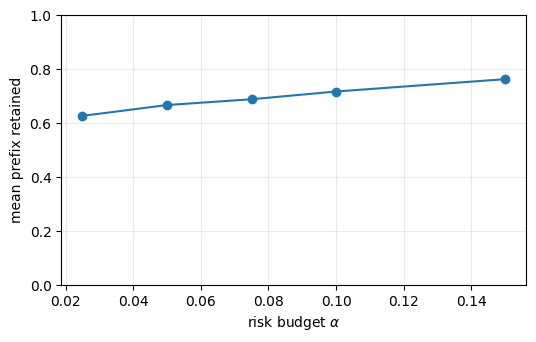

[(0.025, np.float64(0.023333333333333334), np.float64(0.6265595238095238)),
 (0.05, np.float64(0.056666666666666664), np.float64(0.666702380952381)),
 (0.075, np.float64(0.07666666666666666), np.float64(0.6882103174603175)),
 (0.1, np.float64(0.10666666666666667), np.float64(0.7169444444444445)),
 (0.15, np.float64(0.16666666666666666), np.float64(0.7627222222222222))]

In [6]:
alphas = [0.025, 0.05, 0.075, 0.10, 0.15]
rows = []
for alpha in alphas:
    fitted = fit_prefix_calibrator(cal_traces, cal_scores, alpha=alpha)
    lengths = fitted.predict(test_scores)
    risk = prefix_contamination_losses(test_traces, test_scores, fitted.threshold).mean()
    utility = np.mean([m / len(t.steps) for m, t in zip(lengths, test_traces)])
    rows.append((alpha, risk, utility))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot([r[0] for r in rows], [r[2] for r in rows], marker="o")
ax.set(xlabel=r"risk budget $\alpha$", ylabel="mean prefix retained", ylim=(0, 1))
ax.grid(alpha=0.25)
plt.show()
rows

## 7. Move to your data

1. Build one `TraceRecord` per complete sequence (see `crop.data`).
2. Produce one finite error-risk score per ordered step. Do not calibrate and test on steps from the same trace.
3. Fit with `fit_prefix_calibrator(calibration_traces, calibration_scores, alpha=...)`.
4. Save the returned dataclass or its five fields; no learned model weights are created by this layer.
5. Apply `.predict(new_scores)`, retain `steps[:m]`, and route `steps[m:]` for review or repair.
6. Report contamination risk and retained-prefix utility across multiple trace-level splits and alpha values.

For the complete paper pipelines and cached results, continue with `docs/REPRODUCIBILITY.md`.